# Síntesis de dependencia: Pearson, distance correlation y transfer entropy

**Objetivo.** Poner en una sola tabla las tres medidas de dependencia entre cada serie TPM y cada sensor EPM, y ver qué pares dan indicios en varias de ellas a la vez.

**Las tres medidas preguntan cosas distintas:**

| Medida | Pregunta | Momento que compara |
|---|---|---|
| Pearson $\lvert r\rvert$ | ¿Se mueven juntas en línea recta? | El **mismo instante** ($\tau=0$) |
| Distance correlation (dCor) | ¿Hay cualquier tipo de dependencia, lineal o no? | El **mismo instante** ($\tau=0$) |
| TE lineal-gaussiana | ¿El **pasado** del TPM reduce la incertidumbre sobre el **siguiente** valor del EPM, más allá del propio pasado del EPM? | El TPM **antes** que el EPM ($\tau\ge1$) |

Por construcción, Pearson y dCor miden **co-movimiento simultáneo**, y la TE mide **información predictiva adicional**. No se espera que coincidan siempre.

**Criterio objetivo de "pasa la prueba".** Las tres se prueban con **la misma hipótesis nula**: desplazamiento circular del TPM, 199 sustitutos y desplazamiento mínimo de 56 pasos (igual que en `te gaussiana.ipynb`). Un par "pasa" una medida si $p<0.05$. No se usan umbrales fijos como $\lvert r\rvert>0.5$, que serían arbitrarios.

**Advertencias:**
- Pearson y dCor están casi duplicados en estos datos: ordenan los pares casi igual (se verifica en la sección 4). "Pasar las 3" equivale, en la práctica, a **dos líneas de evidencia**: co-movimiento simultáneo e información predictiva.
- No hay corrección por comparaciones múltiples. Por azar se esperan unos $56\times0.05\approx2.8$ pares por medida y versión.
- Los valores de Pearson y dCor pueden diferir un poco de los de `pearson y dcor.ipynb`, porque aquí se usa la rejilla de `te gaussiana.ipynb` (`resample('6h')`) y no `merge_asof`. Se hizo así para que las tres medidas usen exactamente las mismas filas.

**Referencias:**
- Pearson: correlación lineal clásica.
- dCor: Székely, Rizzo y Bakirov (2007), *Ann. Statist.* 35(6), 2769–2794 (clave `szekely2007`).
- TE y sustitutos: ver `te gaussiana.ipynb`.
- Desplazamiento circular: Kugiumtzis (2013), sec. 3.4, que lo aplica a la TE. Usarlo también en Pearson y dCor es una **extensión propia**, justificada porque la nula ("las series no están alineadas en el tiempo") tiene el mismo sentido para cualquier medida de dependencia y conserva la autocorrelación de cada serie.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ARCHIVO_EPM = 'Data_limpia_completa/EPM_completo.csv'
ARCHIVO_TPM = 'Data_limpia_completa/TPM_completo.csv'
ARCHIVO_TE = 'te_gaussiana_resultados.csv'          # sale de te gaussiana.ipynb
ARCHIVO_RESULTADOS = 'sintesis_dependencia_resultados.csv'
BRECHA_INICIO = pd.Timestamp('2023-06-20')
PASO_H = 6
N_SUR = 199
MIN_SHIFT = 56          # igual que en te gaussiana.ipynb
ALFA = 0.05
SEMILLA = 2026

IMG_DIR = Path('img')
IMG_DIR.mkdir(exist_ok=True)

series_tpm = ['POT(1)', 'POT(2)', 'POT(3)', 'POT(4)', 'POT(5)', 'POT(6)', 'POT(7)',
              'Tilt(1)', 'Tilt(2)', 'Tilt(3)', 'Tilt(4)', 'Tilt(5)', 'Tilt(6)', 'Tilt(7)']
series_epm = ['Sensor 1 (5m)', 'Sensor 2 (10m)', 'Sensor 3 (5m)', 'Sensor 4 (10m)']

## 1. Datos: la misma rejilla que la TE

In [2]:
epm_raw = pd.read_csv(ARCHIVO_EPM, parse_dates=['date'])
tpm_raw = pd.read_csv(ARCHIVO_TPM, parse_dates=['date'])
epm_r = (epm_raw[epm_raw['date'] < BRECHA_INICIO]
         .set_index('date').sort_index().resample(f'{PASO_H}h').mean())
tpm_r = (tpm_raw[tpm_raw['date'] < BRECHA_INICIO]
         .drop(columns=['freq']).set_index('date').sort_index().resample(f'{PASO_H}h').mean())
df_niveles = epm_r.join(tpm_r, how='inner')
VERSIONES = {'niveles': df_niveles, 'diferencias': df_niveles.diff().iloc[1:]}
print(f'Posiciones de 6 h: {len(df_niveles)}')

Posiciones de 6 h: 889


## 2. Pearson y dCor con prueba de desplazamiento circular

dCor se calcula por doble centrado de las matrices de distancias (Székely et al., 2007). Desplazar el TPM $w$ pasos equivale a permutar filas y columnas de su matriz centrada. Así la matriz se calcula una sola vez por serie y cada sustituto solo reordena índices.

p-valor: $p=(1+b)/(M+1)$, donde $b$ es el número de sustitutos con valor $\ge$ al observado. El mínimo posible es $0.005$.

In [3]:
def matriz_centrada(v):
    a = np.abs(v[:, None] - v[None, :])
    return a - a.mean(axis=0) - a.mean(axis=1)[:, None] + a.mean()


def dcor_desde_matrices(A, B):
    return float(np.sqrt(max((A * B).mean(), 0.0) / np.sqrt((A * A).mean() * (B * B).mean())))


def p_valor(nula, observado):
    return (1 + int(np.sum(np.asarray(nula) >= observado))) / (len(nula) + 1)


if Path(ARCHIVO_RESULTADOS).exists():
    pd_resultados = pd.read_csv(ARCHIVO_RESULTADOS)
    print(f'Cargado desde cache: {ARCHIVO_RESULTADOS}')
else:
    rng = np.random.default_rng(SEMILLA)
    filas = []
    t0 = time.time()
    for version, d in VERSIONES.items():
        for epm_col in series_epm:
            for tpm_col in series_tpm:
                sub = d[[epm_col, tpm_col]].dropna()
                y, x = sub[epm_col].values, sub[tpm_col].values
                n = len(x)
                A, B = matriz_centrada(x), matriz_centrada(y)
                r_obs = abs(np.corrcoef(x, y)[0, 1])
                dc_obs = dcor_desde_matrices(A, B)
                nula_r, nula_dc = [], []
                for _ in range(N_SUR):
                    idx = np.roll(np.arange(n), rng.integers(MIN_SHIFT, n - MIN_SHIFT + 1))
                    nula_r.append(abs(np.corrcoef(x[idx], y)[0, 1]))
                    nula_dc.append(dcor_desde_matrices(A[np.ix_(idx, idx)], B))
                filas.append({'version': version, 'TPM': tpm_col, 'EPM': epm_col,
                              'abs_r': r_obs, 'p_r': p_valor(nula_r, r_obs),
                              'dcor': dc_obs, 'p_dcor': p_valor(nula_dc, dc_obs)})
        print(f'{version}: listo ({(time.time() - t0) / 60:.1f} min)')
    pd_resultados = pd.DataFrame(filas)
    pd_resultados.to_csv(ARCHIVO_RESULTADOS, index=False)

Cargado desde cache: sintesis_dependencia_resultados.csv


## 3. Tabla unificada y clasificación

Se unen los resultados de la TE (`te_gaussiana_resultados.csv`). Para la TE se usa `p_desplazamiento`, la misma nula que Pearson y dCor. `p_barajado` se muestra solo como referencia.

Categorías:
- **3/3:** pasa Pearson, dCor y TE.
- **TE + una:** pasa la TE y solo una de Pearson o dCor.
- **Solo TE.**
- **Solo simultáneo:** pasa Pearson y/o dCor, pero no la TE. Hay co-movimiento en el mismo instante, sin información predictiva adicional.
- **Ninguna.**

In [4]:
te = pd.read_csv(ARCHIVO_TE)
tabla = pd_resultados.merge(
    te[['version', 'TPM', 'EPM', 'k', 'tau_optimo_horas', 'reduccion_pct', 'p_desplazamiento', 'p_barajado']]
    .rename(columns={'p_desplazamiento': 'p_te', 'p_barajado': 'p_te_barajado'}),
    on=['version', 'TPM', 'EPM'])

pasa_r, pasa_dc, pasa_te = tabla['p_r'] < ALFA, tabla['p_dcor'] < ALFA, tabla['p_te'] < ALFA
tabla['n_pruebas'] = pasa_r.astype(int) + pasa_dc.astype(int) + pasa_te.astype(int)
tabla['categoria'] = np.select(
    [pasa_r & pasa_dc & pasa_te, pasa_te & (pasa_r ^ pasa_dc), pasa_te, pasa_r | pasa_dc],
    ['3/3', 'TE + una', 'solo TE', 'solo simultáneo'], default='ninguna')

conteo = (tabla.groupby(['version', 'categoria']).size().unstack(fill_value=0)
          .reindex(columns=['3/3', 'TE + una', 'solo TE', 'solo simultáneo', 'ninguna'], fill_value=0))
conteo['p<0.05 Pearson'] = (tabla['p_r'] < ALFA).groupby(tabla['version']).sum()
conteo['p<0.05 dCor'] = (tabla['p_dcor'] < ALFA).groupby(tabla['version']).sum()
conteo['p<0.05 TE'] = (tabla['p_te'] < ALFA).groupby(tabla['version']).sum()
conteo

categoria,3/3,TE + una,solo TE,solo simultáneo,ninguna,p<0.05 Pearson,p<0.05 dCor,p<0.05 TE
version,,,,,,,,
diferencias,1,0,0,41,14,35,40,1
niveles,11,1,6,8,30,19,19,18


In [5]:
cols = ['version', 'TPM', 'EPM', 'abs_r', 'p_r', 'dcor', 'p_dcor', 'reduccion_pct', 'p_te', 'tau_optimo_horas', 'n_pruebas', 'categoria']
destacados = tabla[tabla['categoria'].isin(['3/3', 'TE + una', 'solo TE'])]
(destacados[cols].sort_values(['version', 'n_pruebas', 'reduccion_pct'], ascending=[False, False, False])
 .round(3).reset_index(drop=True))

,version,TPM,EPM,abs_r,p_r,dcor,p_dcor,reduccion_pct,p_te,tau_optimo_horas,n_pruebas,categoria
0,niveles,Tilt(4),Sensor 1 (5m),0.547,0.005,0.574,0.005,7.945,0.005,6,3,3/3
1,niveles,Tilt(4),Sensor 3 (5m),0.344,0.030,0.380,0.015,4.273,0.005,78,3,3/3
2,niveles,Tilt(4),Sensor 4 (10m),0.648,0.005,0.630,0.005,2.997,0.005,18,3,3/3
3,niveles,Tilt(3),Sensor 1 (5m),0.461,0.015,0.455,0.005,2.819,0.005,6,3,3/3
4,niveles,Tilt(5),Sensor 4 (10m),0.410,0.010,0.408,0.005,2.708,0.005,18,3,3/3
5,niveles,Tilt(3),Sensor 4 (10m),0.559,0.005,0.533,0.005,2.169,0.005,18,3,3/3
6,niveles,POT(3),Sensor 3 (5m),0.659,0.005,0.674,0.005,1.315,0.005,162,3,3/3
7,niveles,Tilt(2),Sensor 1 (5m),0.703,0.035,0.719,0.030,1.027,0.015,66,3,3/3
8,niveles,Tilt(1),Sensor 1 (5m),0.826,0.005,0.856,0.005,0.380,0.005,138,3,3/3
9,niveles,POT(3),Sensor 1 (5m),0.869,0.005,0.880,0.005,0.373,0.015,132,3,3/3


## 4. ¿Las medidas ordenan los pares de forma parecida?

Correlación de rangos de Spearman sobre los 56 pares. Un valor cercano a 1 indica que ordenan los pares casi igual; uno cercano a 0, que no hay relación entre sus órdenes.

In [6]:
filas = []
for version, g in tabla.groupby('version', sort=False):
    for a, b in [('abs_r', 'dcor'), ('abs_r', 'reduccion_pct'), ('dcor', 'reduccion_pct')]:
        rho, p = spearmanr(g[a], g[b])
        filas.append({'version': version, 'comparacion': f'{a} vs {b}', 'spearman_rho': round(rho, 2), 'p': round(p, 4)})
pd.DataFrame(filas)

,version,comparacion,spearman_rho,p
0,niveles,abs_r vs dcor,0.97,0.0000
1,niveles,abs_r vs reduccion_pct,0.09,0.5136
2,niveles,dcor vs reduccion_pct,0.02,0.8780
3,diferencias,abs_r vs dcor,0.91,0.0000
4,diferencias,abs_r vs reduccion_pct,0.75,0.0000
5,diferencias,dcor vs reduccion_pct,0.70,0.0000


## 5. Mapa: cuántas pruebas pasa cada par (0 a 3)

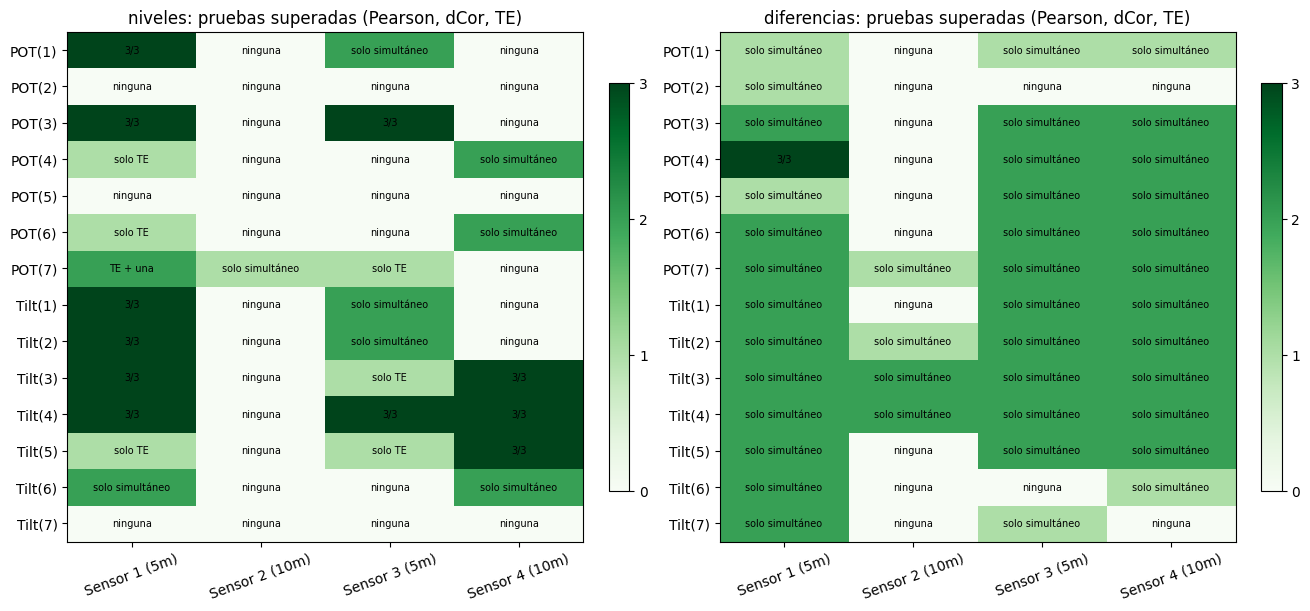

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, version in zip(axes, VERSIONES):
    g = tabla[tabla['version'] == version]
    mat = g.pivot(index='TPM', columns='EPM', values='n_pruebas').loc[series_tpm, series_epm]
    cat = g.pivot(index='TPM', columns='EPM', values='categoria').loc[series_tpm, series_epm]
    im = ax.imshow(mat.values, cmap='Greens', vmin=0, vmax=3, aspect='auto')
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, cat.values[i, j], ha='center', va='center', fontsize=7)
    ax.set_xticks(range(len(series_epm)), series_epm, rotation=20)
    ax.set_yticks(range(len(series_tpm)), series_tpm)
    ax.set_title(f'{version}: pruebas superadas (Pearson, dCor, TE)')
    fig.colorbar(im, ax=ax, shrink=0.8, ticks=[0, 1, 2, 3])
fig.savefig(IMG_DIR / 'sintesis_dependencia_mapa.png', dpi=150)
plt.show()

## 6. Lectura y limitaciones

- **"3/3" es la pista más fuerte disponible**: el par se mueve junto en el mismo instante **y** su pasado aporta información predictiva a 6 h que el EPM no tenía. No prueba que esa serie sirva para imputar la brecha; eso se valida con brechas artificiales.
- **"Solo simultáneo"**: co-movimiento sin anticipación. Para imputar puede seguir siendo útil, porque el MOGP usa la covarianza en el mismo instante, pero no hay evidencia de que el TPM "adelante" al EPM.
- **Pearson y dCor no son evidencia independiente.** Ver el Spearman de la sección 4.
- **Sin corrección múltiple.** Referencia: unos 2.8 pares por azar en cada medida y versión. La coincidencia entre medidas tampoco es independiente, porque comparten series.
- **Estabilidad:** en `pearson y dcor.ipynb` la correlación en niveles cambia entre antes y después de la brecha (por ejemplo, POT(3)–Sensor 4: $r=-0.32$ antes, $+0.72$ después). Esta síntesis usa solo el tramo previo a la brecha.

## 7. Se agrega el CCM: cuatro pruebas

Se incorporan los resultados de `ccm sustitutos.ipynb` (`ccm_resultados.csv`).

**Criterio para el CCM.** Pasa si, en la **dirección de interés** (la variedad del EPM estima el TPM, que es la huella de TPM → EPM), $p_{desplazamiento}<0.05$ **y** la habilidad converge ($\Delta\rho>0$). La misma nula de desplazamiento circular se usa en las cuatro medidas.

También se muestra si pasa la **dirección de control** (la variedad del TPM estima el EPM). Si pasan las dos, la lectura prudente es **dinámica compartida** y no influencia en un solo sentido.

**Advertencia de cuantización.** La columna `vecinos_prom_epm` dice cuántos vecinos usó en promedio la variedad del EPM; lo teórico es $E+1$. Valores mucho mayores (Sensor 4: unos 73 en niveles y unos 337 en diferencias, contra 5 y 3 teóricos) indican que la variedad es casi degenerada. Para ese sensor, el CCM en la dirección de interés **no es interpretable como CCM**: la estimación es casi un promedio global.

In [8]:
ccm = pd.read_csv('ccm_resultados.csv')
ccm_int = ccm[ccm['direccion'].str.startswith('interes')][['version', 'TPM', 'EPM', 'E', 'rho', 'delta_rho', 'p_desplazamiento', 'pasa_ccm']]
ccm_ctl = ccm[ccm['direccion'].str.startswith('control')][['version', 'TPM', 'EPM', 'pasa_ccm']]
ccm_int = ccm_int.rename(columns={'E': 'E_ccm', 'rho': 'rho_ccm', 'delta_rho': 'delta_rho_ccm',
                                  'p_desplazamiento': 'p_ccm'})
ccm_ctl = ccm_ctl.rename(columns={'pasa_ccm': 'pasa_ccm_control'})

# vecinos promedio de la variedad EPM (diagnostico de cuantizacion): valores copiados de la tabla de la seccion 4 de ccm sustitutos.ipynb
vecinos_epm = {'niveles': {'Sensor 1 (5m)': 7.3, 'Sensor 2 (10m)': 11.0, 'Sensor 3 (5m)': 10.1, 'Sensor 4 (10m)': 72.7},
               'diferencias': {'Sensor 1 (5m)': 10.2, 'Sensor 2 (10m)': 6.1, 'Sensor 3 (5m)': 6.2, 'Sensor 4 (10m)': 337.3}}

tabla4 = tabla.merge(ccm_int, on=['version', 'TPM', 'EPM']).merge(ccm_ctl, on=['version', 'TPM', 'EPM'])
tabla4['vecinos_prom_epm'] = [vecinos_epm[v][e] for v, e in zip(tabla4['version'], tabla4['EPM'])]
tabla4['n_pruebas_4'] = tabla4['n_pruebas'] + tabla4['pasa_ccm'].astype(int)

conteo4 = tabla4.groupby('version').agg(
    pasan_4=('n_pruebas_4', lambda s: int((s == 4).sum())),
    pasan_TE_y_CCM=('pasa_ccm', lambda s: int((s & (tabla4.loc[s.index, 'p_te'] < ALFA)).sum())),
    pasa_CCM_interes=('pasa_ccm', 'sum'),
    pasa_CCM_control=('pasa_ccm_control', 'sum'),
)
conteo4

,pasan_4,pasan_TE_y_CCM,pasa_CCM_interes,pasa_CCM_control
version,,,,
diferencias,1,1,27,26
niveles,8,9,14,19


In [9]:
cols4 = ['version', 'TPM', 'EPM', 'abs_r', 'dcor', 'reduccion_pct', 'p_te', 'rho_ccm', 'delta_rho_ccm', 'p_ccm',
         'pasa_ccm_control', 'vecinos_prom_epm', 'n_pruebas_4']
(tabla4[(tabla4['p_te'] < ALFA) & tabla4['pasa_ccm']][cols4]
 .sort_values(['version', 'n_pruebas_4', 'reduccion_pct'], ascending=[False, False, False])
 .round(3).reset_index(drop=True))

,version,TPM,EPM,abs_r,dcor,reduccion_pct,p_te,rho_ccm,delta_rho_ccm,p_ccm,pasa_ccm_control,vecinos_prom_epm,n_pruebas_4
0,niveles,Tilt(4),Sensor 1 (5m),0.547,0.574,7.945,0.005,0.315,0.030,0.005,True,7.3,4
1,niveles,Tilt(4),Sensor 3 (5m),0.344,0.380,4.273,0.005,0.342,0.044,0.010,True,10.1,4
2,niveles,Tilt(4),Sensor 4 (10m),0.648,0.630,2.997,0.005,0.525,0.151,0.005,True,72.7,4
3,niveles,Tilt(5),Sensor 4 (10m),0.410,0.408,2.708,0.005,0.180,0.155,0.045,True,72.7,4
4,niveles,Tilt(3),Sensor 4 (10m),0.559,0.533,2.169,0.005,0.445,0.137,0.005,True,72.7,4
5,niveles,POT(3),Sensor 3 (5m),0.659,0.674,1.315,0.005,0.649,0.035,0.005,True,10.1,4
6,niveles,Tilt(2),Sensor 1 (5m),0.703,0.719,1.027,0.015,0.482,0.083,0.005,False,7.3,4
7,niveles,POT(3),Sensor 1 (5m),0.869,0.880,0.373,0.015,0.599,0.058,0.005,True,7.3,4
8,niveles,POT(7),Sensor 1 (5m),0.686,0.695,1.434,0.005,0.336,0.227,0.010,False,7.3,3
9,diferencias,POT(4),Sensor 1 (5m),0.144,0.184,4.715,0.005,0.332,0.066,0.015,True,10.2,4


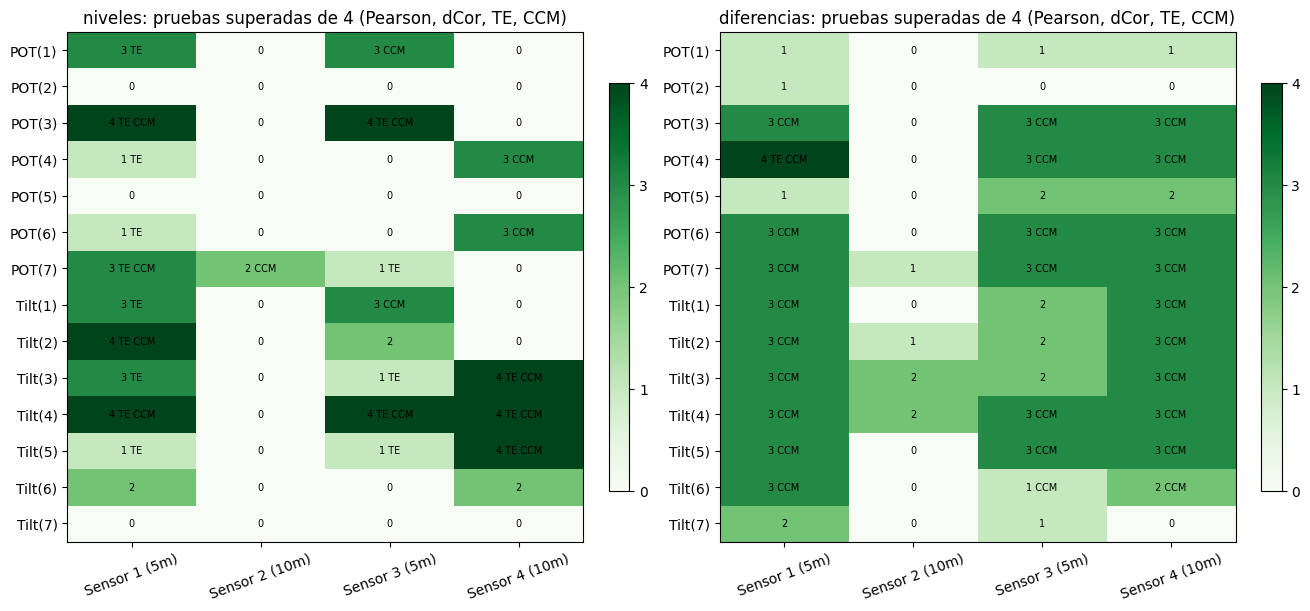

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, version in zip(axes, VERSIONES):
    g = tabla4[tabla4['version'] == version]
    mat = g.pivot(index='TPM', columns='EPM', values='n_pruebas_4').loc[series_tpm, series_epm]
    ccm_mat = g.pivot(index='TPM', columns='EPM', values='pasa_ccm').loc[series_tpm, series_epm]
    te_mat = (g.pivot(index='TPM', columns='EPM', values='p_te') < ALFA).loc[series_tpm, series_epm]
    im = ax.imshow(mat.values, cmap='Greens', vmin=0, vmax=4, aspect='auto')
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            etiqueta = f"{mat.values[i, j]}" + (' TE' if te_mat.values[i, j] else '') + (' CCM' if ccm_mat.values[i, j] else '')
            ax.text(j, i, etiqueta, ha='center', va='center', fontsize=7)
    ax.set_xticks(range(len(series_epm)), series_epm, rotation=20)
    ax.set_yticks(range(len(series_tpm)), series_tpm)
    ax.set_title(f'{version}: pruebas superadas de 4 (Pearson, dCor, TE, CCM)')
    fig.colorbar(im, ax=ax, shrink=0.8, ticks=[0, 1, 2, 3, 4])
fig.savefig(IMG_DIR / 'sintesis_dependencia_mapa_4.png', dpi=150)
plt.show()